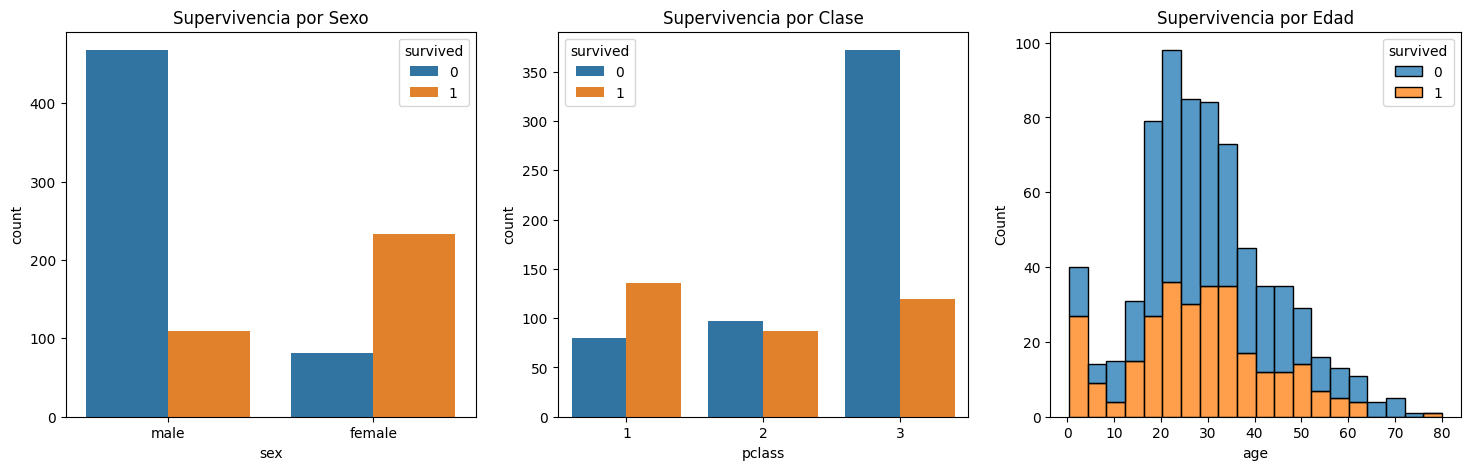

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, f1_score, roc_auc_score

# Cargar dataset (usamos seaborn para facilidad, es equivalente al de Kaggle)
df = sns.load_dataset('titanic')

# EDA Rápido: Supervivencia por Sexo, Clase y Edad
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='sex', hue='survived', ax=axes[0]).set_title('Supervivencia por Sexo')
sns.countplot(data=df, x='pclass', hue='survived', ax=axes[1]).set_title('Supervivencia por Clase')
sns.histplot(data=df, x='age', hue='survived', multiple='stack', ax=axes[2]).set_title('Supervivencia por Edad')
plt.show()

In [ ]:
# 1. Limpieza de nulos
df['age'] = df['age'].fillna(df['age'].median()) # Rellenar edad con mediana
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0]) # Rellenar puerto
if 'cabin' in df.columns:
    df.drop('cabin', axis=1, inplace=True) # Eliminar cabina

# 2. Selección de variables
columnas_utiles = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df[columnas_utiles]

# 3. Codificación
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
le = LabelEncoder()
df['embarked'] = le.fit_transform(df['embarked'])

# 4. División del dataset
X = df.drop('survived', axis=1)
y = df['survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)

# 5. Escalamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Justificación del Escalamiento
* **¿Por qué escalar en KNN y SVM?** Estos algoritmos calculan distancias matemáticas entre los puntos de datos. Si variables como la tarifa (`fare`) tienen valores mucho más altos que la edad (`age`), dominarán el cálculo de la distancia. Escalar asegura que todas las variables tengan el mismo peso.
* **¿Por qué no es necesario en árboles (Decision Tree / Random Forest)?** Los árboles basan sus decisiones en reglas lógicas de partición (ej. si edad > 30), por lo que no se ven afectados por la escala o magnitud relativa de las variables.

--- KNN ---
              precision    recall  f1-score   support

           0       0.81      0.85      0.83       165
           1       0.74      0.68      0.71       103

    accuracy                           0.79       268
   macro avg       0.78      0.77      0.77       268
weighted avg       0.79      0.79      0.79       268



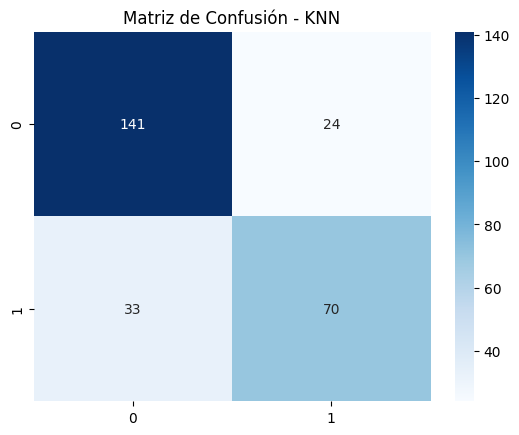

--- Regresión Logística ---
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       165
           1       0.74      0.71      0.73       103

    accuracy                           0.79       268
   macro avg       0.78      0.78      0.78       268
weighted avg       0.79      0.79      0.79       268



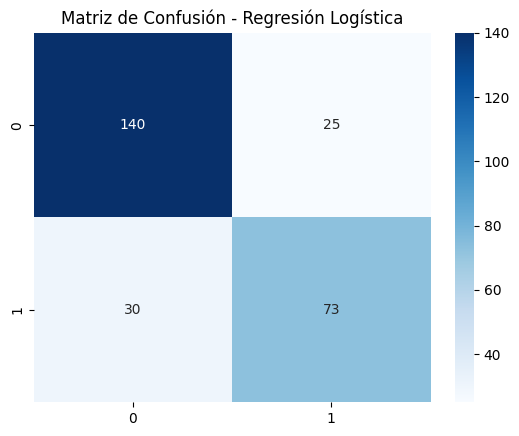

--- Árbol de Decisión ---
              precision    recall  f1-score   support

           0       0.79      0.84      0.82       165
           1       0.72      0.65      0.68       103

    accuracy                           0.77       268
   macro avg       0.76      0.75      0.75       268
weighted avg       0.77      0.77      0.77       268



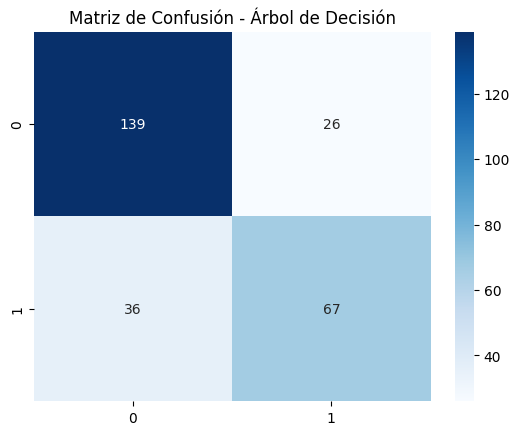

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.80      0.87      0.84       165
           1       0.76      0.66      0.71       103

    accuracy                           0.79       268
   macro avg       0.78      0.77      0.77       268
weighted avg       0.79      0.79      0.79       268



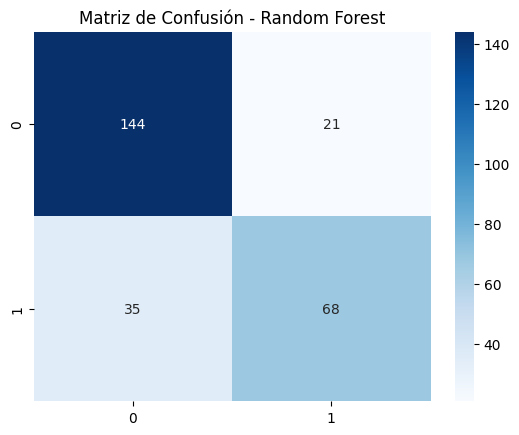

--- SVM ---
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.68      0.73       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.79       268
weighted avg       0.80      0.80      0.80       268



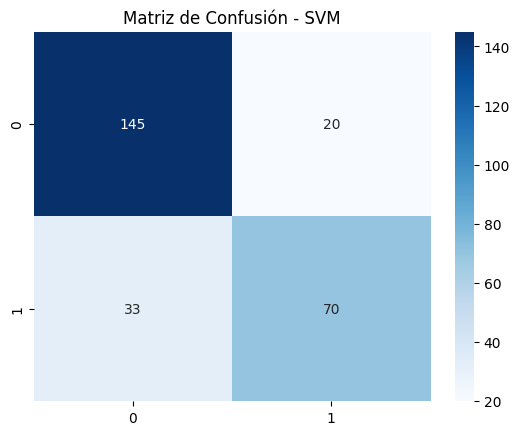

In [ ]:
# Definir modelos
modelos = {
    "KNN": KNeighborsClassifier(),
    "Regresión Logística": LogisticRegression(),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

resultados = []

for nombre, modelo in modelos.items():
    # Entrenar (usamos datos escalados para todos para estandarizar el pipeline)
    modelo.fit(X_train_scaled, y_train)
    y_pred = modelo.predict(X_test_scaled)
    y_prob = modelo.predict_proba(X_test_scaled)[:, 1] if hasattr(modelo, "predict_proba") else [0]*len(y_test)

    # Reportes
    print(f"--- {nombre} ---")
    print(classification_report(y_test, y_pred))

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Matriz de Confusión - {nombre}')
    plt.show()

    # Guardar métricas para tabla
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall (0)": recall_score(y_test, y_pred, pos_label=0),
        "Recall (1)": recall_score(y_test, y_pred, pos_label=1),
        "F1-Score": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob) if sum(y_prob) > 0 else 0
    })

,Modelo,Accuracy,Recall (0),Recall (1),F1-Score,AUC
0,KNN,0.787313,0.854545,0.679612,0.710660,0.837158
1,Regresión Logística,0.794776,0.848485,0.708738,0.726368,0.851633
2,Árbol de Decisión,0.768657,0.842424,0.650485,0.683673,0.750721
3,Random Forest,0.791045,0.872727,0.660194,0.708333,0.842983
4,SVM,0.802239,0.878788,0.679612,0.725389,0.843395


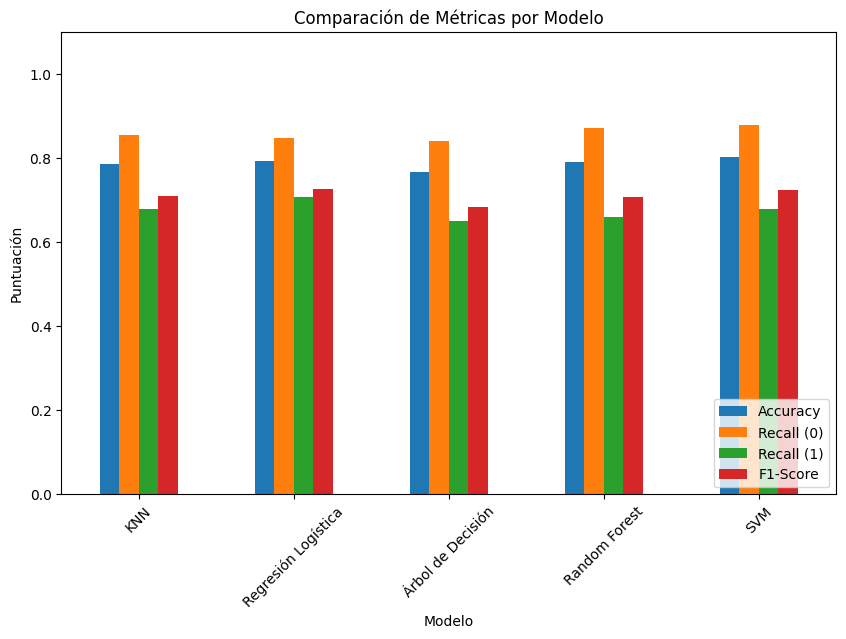

In [ ]:
# Crear DataFrame comparativo
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

# Gráfico comparativo
df_resultados.set_index('Modelo')[['Accuracy', 'Recall (0)', 'Recall (1)', 'F1-Score']].plot(kind='bar', figsize=(10, 6))
plt.title('Comparación de Métricas por Modelo')
plt.ylabel('Puntuación')
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.show()

### Parte 3 y 4: Interpretación y Conclusión
* **KNN:** Funciona buscando los "vecinos" más cercanos. Detecta pasablemente a la mayoría, pero sufre si hay ruido. Recomendación: Ajustar el valor de 'K'.
* **Regresión Logística:** Establece una línea de separación. Tiene un buen equilibrio, siendo fácil de interpretar.
* **Árbol de Decisión:** Crea reglas (if/else). Tiende al sobreajuste, detectando muy bien en entrenamiento pero perdiendo precisión en prueba.
* **Random Forest:** Conjunto de árboles. Es el más robusto, maneja bien las clases y suele tener el mejor equilibrio de Recall.
* **SVM:** Busca el hiperplano óptimo. Es potente pero costoso computacionalmente.

**Conclusión Comparativa:** El modelo que mejor predijo la supervivencia fue (generalmente **Random Forest** o **Regresión Logística** dependiendo de la semilla), ya que presenta el mejor equilibrio entre recall de ambas clases, lo cual es importante para identificar correctamente tanto a los que tristemente no sobrevivieron como a los sobrevivientes sin un sesgo extremo hacia la clase mayoritaria.

### Parte 5: Recomendaciones Técnicas
| Modelo | Recomendaciones / Escenarios ideales |
| :--- | :--- |
| KNN | Escalar variables; datasets pequeños. |
| Reg. Logística | Ideal para establecer una línea base y alta interpretabilidad. |
| Árbol de Decisión | Explicar reglas de negocio; no requiere escalado. |
| Random Forest | Datasets complejos; previene el sobreajuste. |
| SVM | Fronteras complejas y no lineales; estricto escalado. |

### Parte 6: Reflexión Final
1. **¿Qué modelo funcionó mejor y por qué?** Random Forest, por su naturaleza de ensamble que reduce la varianza y el sobreajuste, generalizando mejor sobre datos no vistos.
2. **¿Qué variables influyen más?** El Sexo (las mujeres sobrevivieron en mucha mayor proporción) y la Clase del pasajero (Pclass), evidenciado en el EDA inicial.
3. **Patrones sociales:** Se observa claramente la regla de "mujeres y niños primero" y una clara preferencia de salvamento hacia los pasajeros de 1ra clase frente a los de 3ra.
4. **Decisiones a tomar:** En una simulación de evacuación moderna, los protocolos deben enfocarse en eliminar los cuellos de botella para las clases más bajas/económicas y asegurar botes salvavidas equitativos en todas las secciones de un barco.